# Notebook 01 · Integración de dimensiones ENDES 2025
**Proyecto:** predicción de la desnutrición crónica infantil con XGBoost · IS-484 Inteligencia Artificial I · UNSCH

**Qué hace este notebook (y qué no):**
1. Inventaría los módulos descargados en `1 datos`.
2. Elige **42 variables candidatas**, ordenadas por prioridad y agrupadas por tema, y explica por qué entra cada una.
3. Cruza las tablas por sus llaves hasta tener **una fila por niño menor de 5 años**.
4. Reemplaza los códigos ENDES (`HV213`, `M19`, …) por nombres claros.
5. Define las dos variables objetivo y guarda el dataset **sin limpiar** en `3 datos_procesados`.

La selección final (las variables que se quedan en el modelo) se decide **después de entrenar**, mirando la importancia por ganancia y SHAP. Aquí solo se reúnen las candidatas más relevantes; la limpieza y el EDA van en los notebooks siguientes.

## 1. Configuración

In [1]:
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore", category=pd.errors.PerformanceWarning)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_rows", 200)
pd.set_option("display.max_colwidth", 90)
pd.set_option("display.width", 170)

RAIZ = Path.cwd().parent if Path.cwd().name == "2 notebooks" else Path.cwd()
DATOS = RAIZ / "1 datos"
SALIDA = RAIZ / "3 datos_procesados"
SALIDA.mkdir(exist_ok=True)
assert DATOS.exists(), f"No se encontró la carpeta de datos: {DATOS}"
print("Datos  :", DATOS)
print("Salida :", SALIDA)

Datos  : D:\UNSCH\400 (2026 - II)\IA\Proyecto_Desnutricion_Cronica_Infantil_XGBOOST\1 datos
Salida : D:\UNSCH\400 (2026 - II)\IA\Proyecto_Desnutricion_Cronica_Infantil_XGBOOST\3 datos_procesados


## 2. Inventario de lo descargado
Cada archivo es una tabla distinta. Lo importante es **a quién describe** (niño, madre, hogar o persona del hogar), porque de eso depende cómo se cruza.

In [2]:
# clave: (ruta relativa, a quién describe, llave principal)
ARCHIVOS = {
    # --- Niño menor de 5 años (cuestionario individual de la madre)
    "REC44":    ("anemia/REC44_2025.csv",                 "Niño <5 (medidas y hemoglobina)",        "CASEID + HWIDX"),
    "REC21":    ("Hist Nacimiento/REC21_2025.csv",        "Hijo (historia de nacimientos)",         "CASEID + BIDX"),
    "REC41":    ("embarazo/REC41_2025.csv",               "Niño <5 (embarazo, parto, lactancia)",   "CASEID + MIDX"),
    "REC94":    ("embarazo/REC94_2025.csv",               "Niño <5 (embarazo y lactancia ampliado)", "CASEID + IDX94"),
    "REC43":    ("Inmunización y Salud/REC43_2025.csv",   "Niño <5 (vacunas, enfermedades)",        "CASEID + HIDX"),
    "REC95":    ("Inmunización y Salud/REC95_2025.csv",   "Niño <5 (CRED, hierro, vacunas)",        "CASEID + IDX95"),
    "DIT":      ("Inmunización y Salud/DIT_2025.csv",     "Niño (desarrollo infantil temprano)",    "CASEID + BIDX"),
    # --- Madre (mujer en edad fértil)
    "REC0111":  ("MEF/REC0111_2025.dta",                  "Madre (datos básicos, riqueza)",         "CASEID"),
    "REC91":    ("MEF/REC91_2025.dta",                    "Madre (preguntas ampliadas de Perú)",    "CASEID"),
    "RE223132": ("Hist Nacimiento/RE223132_2025.csv",     "Madre (fecundidad)",                     "CASEID"),
    "REC42":    ("Inmunización y Salud/REC42_2025.csv",   "Madre (último hijo, seguro)",            "CASEID"),
    "RECH5":    ("anemia/RECH5_2025.csv",                 "Madre (talla, IMC, hemoglobina)",        "HHID + HA0"),
    # --- Niño medido en el hogar
    "RECH6":    ("anemia/RECH6_2025.csv",                 "Niño <5 (medidas, cuestionario hogar)",  "HHID + HC0"),
    # --- Personas del hogar
    "RECH1":    ("hogar/RECH1_2025.csv",                  "Persona del hogar (parentesco, edad)",   "HHID + HVIDX"),
    "RECH4":    ("hogar/RECH4_2025.csv",                  "Persona del hogar (seguro, actividad)",  "HHID + IDXH4"),
    "RECHM":    ("hogar/RECHM_2025.csv",                  "Fallecidos del hogar",                   "HHID + NRO_ORDEN_ID"),
    # --- Hogar / vivienda
    "RECH0":    ("hogar/RECH0_2025.csv",                  "Hogar (tamaño, altitud)",                "HHID"),
    "RECH23":   ("vivienda/RECH23_2025.csv",              "Vivienda (agua, saneamiento, material)", "HHID"),
    "PS_HOGAR": ("Programas Sociales/Programas Sociales x Hogar_2025.csv", "Hogar (programas sociales)", "HHID"),
    # --- Programas sociales por persona
    "PS_VL":        ("Programas Sociales/PS_VL_2025.csv",              "Persona (Vaso de Leche)",  "HHID + HVIDX"),
    "PS_QALIWARMA": ("Programas Sociales/PS_QALIWARMA_2025.csv",       "Persona (Qali Warma)",     "HHID + HVIDX"),
    "PS_CUNAMAS":   ("Programas Sociales/PS_CUNAMAS_VISITA_2025.csv",  "Persona (Cuna Más)",       "HHID + HVIDX"),
    "PS_WAWAWASI":  ("Programas Sociales/PS_WAWAWASI_2025.csv",        "Persona (Wawa Wasi)",      "HHID + HVIDX"),
    "PS_COMEDOR":   ("Programas Sociales/PS_COMEDOR_2025.csv",         "Persona (Comedor popular)", "HHID + HVIDX"),
    "PS_PENSION65": ("Programas Sociales/PS_PENSION65_2025.csv",       "Persona (Pensión 65)",     "HHID + HVIDX"),
    "PS_BECA18":    ("Programas Sociales/PS_BECA18_2025.csv",          "Persona (Beca 18)",        "HHID + HVIDX"),
    "PS_TRABAJA":   ("Programas Sociales/PS_TRABAJA_2025.csv",         "Persona (Trabaja Perú)",   "HHID + HVIDX"),
}
USADAS = {"REC44", "REC21", "REC41", "REC94", "REC43", "REC95", "REC0111", "REC91", "RE223132",
          "RECH5", "RECH6", "RECH4", "RECH0", "RECH23", "PS_HOGAR"}


def dimensiones(ruta):
    if ruta.suffix == ".dta":
        return pd.read_stata(ruta, convert_categoricals=False).shape
    with open(ruta, "rb") as f:
        filas = sum(1 for _ in f) - 1
    return filas, len(pd.read_csv(ruta, nrows=0, encoding="utf-8-sig").columns)


inventario = []
for clave, (ruta, nivel, llave) in ARCHIVOS.items():
    filas, cols = dimensiones(DATOS / ruta)
    inventario.append({"tabla": clave, "archivo": Path(ruta).parent.name + "/" + Path(ruta).name,
                       "describe a": nivel, "llave": llave, "filas": filas, "columnas": cols,
                       "uso": "se usa" if clave in USADAS else "descartada"})
inventario = pd.DataFrame(inventario)
inventario

,tabla,archivo,describe a,llave,filas,columnas,uso
0,REC44,anemia/REC44_2025.csv,Niño <5 (medidas y hemoglobina),CASEID + HWIDX,18841,34,se usa
1,REC21,Hist Nacimiento/REC21_2025.csv,Hijo (historia de nacimientos),CASEID + BIDX,57196,34,se usa
2,REC41,embarazo/REC41_2025.csv,"Niño <5 (embarazo, parto, lactancia)",CASEID + MIDX,18841,147,se usa
3,REC94,embarazo/REC94_2025.csv,Niño <5 (embarazo y lactancia ampliado),CASEID + IDX94,18841,61,se usa
4,REC43,Inmunización y Salud/REC43_2025.csv,"Niño <5 (vacunas, enfermedades)",CASEID + HIDX,18841,168,se usa
5,REC95,Inmunización y Salud/REC95_2025.csv,"Niño <5 (CRED, hierro, vacunas)",CASEID + IDX95,18841,315,se usa
6,DIT,Inmunización y Salud/DIT_2025.csv,Niño (desarrollo infantil temprano),CASEID + BIDX,18470,63,descartada
7,REC0111,MEF/REC0111_2025.dta,"Madre (datos básicos, riqueza)",CASEID,36260,103,se usa
8,REC91,MEF/REC91_2025.dta,Madre (preguntas ampliadas de Perú),CASEID,36260,343,se usa
9,RE223132,Hist Nacimiento/RE223132_2025.csv,Madre (fecundidad),CASEID,32700,150,se usa


**Lectura:** hay 27 tablas y más de 2 600 columnas. No se puede entrenar con todo: hay que quedarse con las que describen causas o factores de riesgo de la desnutrición crónica.

## 3. Unidad de análisis y mapa de relaciones
**Unidad de análisis:** un niño menor de 5 años con talla medida (tabla `REC44`, 18 841 niños).

```
REC44 (niño) ──CASEID+HWIDX──► REC21, REC41, REC94, REC43, REC95   (nacimiento, lactancia, salud)
     │
     ├─CASEID──► REC0111, REC91, RE223132   (madre: edad, educación, lengua, región, primer parto)
     │              │
     │              ├─ hhid ──► RECH0, RECH23, PS_HOGAR           (hogar, vivienda, programas)
     │              └─ hhid + línea de la madre ──► RECH5         (talla e IMC de la madre)
     │
     └─ hhid + línea madre + edad + sexo ──► RECH6 ──► línea del niño ──► RECH4   (intervalo entre hijos, seguro SIS)
```

Regla de oro de cada cruce: **la tabla base nunca cambia de tamaño** (siempre 18 841 filas). Se verifica con `assert` y se informa el % de niños que encontró pareja.

## 4. Selección de dimensiones
**Criterios.** Una variable entra como candidata si:
- la literatura (OMS, UNICEF, informes ENDES) la señala como factor de la desnutrición crónica,
- está disponible para casi todos los niños,
- **no contiene la respuesta**: se excluyen el puntaje Z (`HW70`) como predictor, y el peso, la talla y las demás medidas antropométricas del niño con las que se calcula (*data leakage*).

Son **42 candidatas** en 8 temas, ordenadas por prioridad. Cada fila del catálogo indica: tema · tabla de origen · persona (a quién describe la fila cruzada) · código ENDES · nombre final · significado y códigos especiales. Más abajo se le agrega el **rol en el modelo** (`id`, `grupo`, `peso`, `feature`, `target`, `excluir`). Los significados se contrastaron con los diccionarios PDF (algunos vienen desordenados) y con los valores reales de cada columna.

Las variables **no** pasan por una tabla ancha intermedia: cada tabla se lee solo con las columnas elegidas.

In [3]:
# (bloque, tabla, persona, codigo_original, nombre_final, descripcion)
# persona = a quién describe la fila de la tabla cruzada ("" = ya es del niño/madre/hogar; "nino" = fila del niño en el listado del hogar)
CATALOGO = [
 # ---------- Llaves e identificación (no son predictoras)
 ("Llaves", "REC44",   "", "CASEID", "caseid",            "Identificador de la madre entrevistada"),
 ("Llaves", "REC44",   "", "HWIDX",  "idx_historia_nino", "N° del niño en la historia de nacimientos (llave entre tablas del niño)"),
 ("Llaves", "REC0111", "", "HHID",   "hhid",              "Identificador del hogar"),
 ("Llaves", "REC0111", "", "V003",   "linea_madre_hogar", "N° de línea de la madre en el listado del hogar"),
 ("Llaves", "RECH6",   "", "HC0",    "linea_nino_hogar",  "N° de línea del niño en el listado del hogar"),
 ("Llaves", "REC0111", "", "V001",   "conglomerado",      "Conglomerado muestral (sirve para dividir train/test por grupos)"),
 ("Llaves", "REC0111", "", "V005",   "factor_ponderacion","Factor de expansión de la madre (dividir entre 1 000 000); solo para inferencia poblacional"),
 # ---------- Objetivo (valor crudo)
 ("Objetivo", "REC44", "", "HW70", "talla_edad_dest_x100", "Talla/Edad en desviaciones estándar OMS ×100 (-235 = -2.35). 9996-9998 = no válido. NO es predictora"),

 # ===== 1-2. Niño
 ("Niño", "REC44", "", "HW1",  "edad_meses",       "Edad del niño en meses (0-59)"),
 ("Niño", "REC21", "", "B4",   "sexo_nino",        "1 = hombre, 2 = mujer"),
 ("Niño", "REC21", "", "BORD", "orden_nacimiento", "Orden de nacimiento entre los hijos de la madre"),
 ("Niño", "RECH6", "", "HC63", "intervalo_nac_previo_meses", "Meses desde el nacimiento anterior. Vacío = primogénito o niño sin pareja en el puente (el código 999 de RECH6 no aparece en este dataset)"),
 ("Niño", "REC44", "", "HW57", "nivel_anemia_nino", "Anemia con hemoglobina YA ajustada por altitud (RM 363-2022-MINSA): 1 grave, 2 moderada, 3 leve, 4 sin anemia, 9 = no medida (casi todos menores de 6 meses)"),

 # ===== 5. Embarazo y parto
 ("Embarazo y parto", "REC41", "", "M19", "peso_nacer_g",       "Peso al nacer en gramos (9996 = no se pesó, 9998 = no sabe)"),
 ("Embarazo y parto", "REC41", "", "M14", "visitas_prenatales", "N° de controles prenatales (98 = no sabe)"),
 ("Embarazo y parto", "REC41", "", "M45", "hierro_embarazo",    "Recibió hierro en el embarazo: 0 no, 1 sí, 8 no sabe"),
 ("Embarazo y parto", "REC41", "", "M18", "tamano_percibido_nacer", "Tamaño al nacer según la madre: 1 muy grande, 2 más grande que el promedio, 3 promedio, 4 más pequeño, 5 muy pequeño, 8 no sabe (respaldo de peso_nacer_g)"),
 ("Embarazo y parto", "REC41", "", "M15", "lugar_parto",        "Lugar del parto (11-12 domicilio, 21-27 establecimiento público, 31-32 privado, 41-42 ONG/iglesia, 96 otro)"),

 # ===== 6. Lactancia
 ("Lactancia", "REC41", "", "M5",     "meses_lactancia",       "Meses de lactancia (94 = nunca amamantó, 98 = no sabe; el código 95 'aún amamanta' no aparece en 2025)"),
 ("Lactancia", "REC94", "", "QI440B", "lactancia_exclusiva_6m","Solo leche materna los primeros 6 meses: 1 sí, 2 no, 8 no sabe (vacío si el niño aún no los cumple)"),

 # ===== 7. Enfermedades recientes
 ("Enfermedades recientes", "REC43", "", "H11", "diarrea_2sem", "Diarrea: 0 no, 1 últimas 24 h, 2 últimas 2 semanas, 8 no sabe"),
 ("Enfermedades recientes", "REC43", "", "H31", "tos_2sem",     "Tos (indicador de infección respiratoria, IRA): 0 no, 1 últimas 24 h, 2 últimas 2 semanas, 8 no sabe"),

 # ===== 8. Salud y suplementación del niño
 ("Salud del niño", "REC95", "", "S466C",  "n_controles_cred",         "N° de controles de crecimiento y desarrollo, CRED (98 = no sabe)"),
 ("Salud del niño", "REC95", "", "S465EA", "hierro_jarabe_7d",         "Tomó hierro en jarabe en los últimos 7 días: 1 sí, 2 no, 8 no sabe"),
 ("Salud del niño", "REC95", "", "S465EC", "micronutrientes_polvo_7d", "Tomó micronutrientes en polvo (chispitas) en los últimos 7 días: 1 sí, 2 no, 8 no sabe"),
 ("Salud del niño", "REC43", "", "H43",    "antiparasitario_12m",      "Antiparasitarios en los últimos 12 meses (ventana confirmada en el diccionario INEI de REC43): 0 no, 1 sí"),
 ("Salud del niño", "REC43", "", "H7",     "vacuna_dpt3",              "DPT/pentavalente 3ra dosis: 0 no; 1, 2 y 3 = sí (fecha en carné / lo reporta la madre / marcada en carné; se unifican en 1); 8 no sabe"),
 ("Salud del niño", "REC43", "", "H8",     "vacuna_polio3",            "Polio 3ra dosis (mismos códigos; 1-3 se unifican en 1)"),
 ("Salud del niño", "REC43", "", "H9",     "vacuna_sarampion",         "Sarampión/SPR (mismos códigos; 1-3 se unifican en 1)"),

 # ===== 3-4. Madre
 ("Madre", "REC0111", "", "V012", "edad_madre",             "Edad de la madre en años"),
 ("Madre", "RE223132","", "V212", "edad_primer_parto",      "Edad de la madre al primer parto"),
 ("Madre", "REC0111", "", "V106", "nivel_educativo_madre",  "0 sin educación, 1 primaria, 2 secundaria, 3 superior"),
 ("Madre", "REC0111", "", "V131", "lengua_materna_madre",   "Lengua materna: 1 quechua, 2 aimara, 3 ashaninka, 4 awajún, 5 shipibo, 6 shawi, 7 matsigenka, 8 achuar, 9 otra nativa, 10 castellano, 11-13 otras"),
 ("Madre", "RECH5",   "", "HA3",  "talla_madre_x10",        "Talla de la madre en cm ×10 (1510 = 151.0). 9999 = no medida"),
 ("Madre", "RECH5",   "", "HA40", "imc_madre_x100",         "Índice de masa corporal de la madre ×100 (2500 = 25.0). 9999 = no medido"),

 # ===== 2, 9. Geografía, hogar y vivienda
 ("Hogar y geografía", "REC0111", "", "V190",  "quintil_riqueza",   "Índice de riqueza: 1 más pobre … 5 más rico"),
 ("Hogar y geografía", "REC0111", "", "V025",  "area_residencia",   "1 urbano, 2 rural"),
 ("Hogar y geografía", "REC0111", "", "V024",  "departamento",      "Departamento de residencia (código 1-25)"),
 ("Hogar y geografía", "REC91",   "", "SREGION","region_natural",   "1 Lima Metropolitana, 2 resto de la Costa, 3 Sierra, 4 Selva"),
 ("Hogar y geografía", "RECH0",   "", "HV040", "altitud_msnm",      "Altitud del conglomerado en metros sobre el nivel del mar"),
 ("Hogar y geografía", "RECH23",  "", "HV205", "tipo_servicio_higienico", "11-12 red pública, 21 letrina ventilada, 22 pozo séptico, 23 pozo ciego, 24 colgante, 31 río/acequia, 32 sin servicio, 96 otro"),
 ("Hogar y geografía", "RECH23",  "", "HV201", "fuente_agua_beber", "Fuente de agua para beber (11 red dentro de la vivienda, 12 red fuera, 13 pilón, 21-22 pozo, 41 manantial, 43 río/acequia, 61 camión cisterna, 71 embotellada, 96 otro)"),
 ("Hogar y geografía", "RECH23",  "", "SH227", "cloro_residual_agua","Prueba de cloro en el agua: 1 ≥0.5 mg/L, 2 0.1-0.5 mg/L, 3 0.0 mg/L, 4 sin tratar (río, pozo), 5 embotellada, 9 no se pudo medir; el código 6 (1 178 casos) no figura en el diccionario INEI y se deja como NaN. Es categórica: no es una concentración"),
 ("Hogar y geografía", "RECH23",  "", "HV226", "combustible_cocinar","Combustible para cocinar (2 gas, 3 gas natural, 7 carbón, 8 leña, 95 no cocina, otros)"),
 ("Hogar y geografía", "RECH23",  "", "HV213", "material_piso",     "11 tierra, 21 madera, 31-34 cemento/loseta/parquet/láminas, 96 otro"),
 ("Hogar y geografía", "RECH23",  "", "HV216", "n_dormitorios",     "Habitaciones usadas para dormir (insumo de hacinamiento)"),
 ("Hogar y geografía", "RECH0",   "", "HV009", "n_miembros_hogar",  "Total de personas en el hogar (insumo de hacinamiento)"),
 ("Hogar y geografía", "RECH0",   "", "HV014", "n_menores_5_hogar", "Niños menores de 5 años en el hogar"),
 ("Hogar y geografía", "derivada", "", "n_miembros_hogar / n_dormitorios", "hacinamiento", "Personas por dormitorio (se calcula abajo)"),

 # ===== 10. Programas sociales y seguro
 ("Programas y seguro", "PS_HOGAR", "", "QH95",  "hogar_juntos",     "Algún miembro recibe Juntos: 1 sí, 2 no, 8 no sabe"),
 ("Programas y seguro", "PS_HOGAR", "", "QH101", "hogar_vaso_leche", "Algún miembro recibe Vaso de Leche: 1 sí, 2 no, 8 no sabe"),
 ("Programas y seguro", "RECH4", "nino", "SH11C", "seguro_nino_sis", "El niño tiene SIS: 0 no, 1 sí"),
]

COLS = ["bloque", "tabla", "persona", "codigo", "nombre", "descripcion"]
CAT = pd.DataFrame(CATALOGO, columns=COLS)
assert CAT["nombre"].is_unique, "Hay nombres finales repetidos"

# ---- Rol de cada columna en el modelo
ROL = {n: "feature" for n in CAT.nombre}
ROL.update({"caseid": "id", "hhid": "id",                              # solo identifican
            "conglomerado": "grupo",                                  # para dividir train/test por grupos
            "factor_ponderacion": "peso",                             # sample_weight (opcional)
            "talla_edad_dest_x100": "excluir",                        # fuga: es el puntaje Z
            "idx_historia_nino": "excluir", "linea_madre_hogar": "excluir", "linea_nino_hogar": "excluir",  # llaves de cruce
            "n_miembros_hogar": "excluir", "n_dormitorios": "excluir"})                                    # insumos de hacinamiento
ROL.update({"haz": "excluir", "desnutricion_cronica": "target"})      # haz = fuga en clasificación (target solo del notebook de regresión)
CAT["rol"] = CAT["nombre"].map(ROL)

# ---- Tipo de variable: las categorías nominales NO son escalas numéricas
CATEGORICAS = ["departamento", "region_natural", "lengua_materna_madre", "fuente_agua_beber", "material_piso",
               "combustible_cocinar", "lugar_parto", "tipo_servicio_higienico", "cloro_residual_agua"]
CAT["tipo"] = np.where(CAT.nombre.isin(CATEGORICAS), "categórica", "numérica")
CAT.loc[CAT.rol.isin(["id", "grupo"]), "tipo"] = "identificador"

IDS = ["caseid", "hhid", "conglomerado", "factor_ponderacion"]
INSUMOS = ["n_miembros_hogar", "n_dormitorios"]
candidatas = [n for n in CAT.nombre if ROL[n] == "feature"]
assert len(candidatas) == 42, len(candidatas)

resumen = CAT[CAT.rol == "feature"].groupby("bloque", sort=False).nombre.apply(lambda s: ", ".join(s))
resumen.rename("features").to_frame()

,features
bloque,
Niño,"edad_meses, sexo_nino, orden_nacimiento, intervalo_nac_previo_meses, nivel_anemia_nino"
Embarazo y parto,"peso_nacer_g, visitas_prenatales, hierro_embarazo, tamano_percibido_nacer, lugar_parto"
Lactancia,"meses_lactancia, lactancia_exclusiva_6m"
Enfermedades recientes,"diarrea_2sem, tos_2sem"
Salud del niño,"n_controles_cred, hierro_jarabe_7d, micronutrientes_polvo_7d, antiparasitario_12m, vac..."
Madre,"edad_madre, edad_primer_parto, nivel_educativo_madre, lengua_materna_madre, talla_madr..."
Hogar y geografía,"quintil_riqueza, area_residencia, departamento, region_natural, altitud_msnm, tipo_ser..."
Programas y seguro,"hogar_juntos, hogar_vaso_leche, seguro_nino_sis"


### 4.1 Por qué entra cada grupo
| Tema | Variables | Razón |
|---|---|---|
| **Niño** | edad, sexo, orden de nacimiento, intervalo entre hijos, anemia | La prevalencia sube en los dos primeros años y luego baja (relación no lineal con la edad); los varones tienen mayor prevalencia; los hermanos cercanos compiten por recursos; la anemia marca carencia nutricional |
| **Madre** | talla, IMC, edad, edad al primer parto, educación, lengua materna | La talla materna es el predictor más fuerte (transmisión intergeneracional); la lengua materna recoge la brecha cultural y de acceso, muy marcada en Perú |
| **Geografía y hogar** | riqueza, área, departamento, región natural, altitud, saneamiento, agua, cloro, combustible, piso, hacinamiento | Pobreza, entorno y condiciones de saneamiento; la región natural y el departamento captan efectos que la altitud sola no explica |
| **Embarazo y parto** | peso al nacer, controles prenatales, hierro, lugar del parto | El bajo peso al nacer es el principal antecedente; la atención prenatal y el parto institucional reflejan acceso a salud |
| **Lactancia** | meses de lactancia, lactancia exclusiva | Protección nutricional en los primeros 6 meses |
| **Enfermedades** | diarrea, tos (IRA) | Las infecciones repetidas frenan el crecimiento |
| **Salud del niño** | CRED, hierro, micronutrientes, antiparasitario, vacunas | Contacto con el sistema de salud y prevención de anemia |
| **Programas y seguro** | Juntos, Vaso de Leche, SIS | Miden acceso; su efecto es ambiguo (los reciben hogares más pobres), por eso se evaluarán con el modelo |

### 4.2 Lo que se deja fuera
| Tabla | Qué se descarta | Motivo |
|---|---|---|
| `REC44`, `RECH6` | Peso, talla, percentiles y demás medidas del niño (`HW2-HW12`, `HW71-HW73`, `HC1-HC73`) | **Fuga de datos**: el puntaje Z se calcula con ellas |
| `DIT`, `RECHM`, `RECH1`, `REC42` | Toda la tabla | Desarrollo infantil (más de 90 % vacía), fallecidos del hogar, parentesco y alimentación del último hijo (solo cubre un hijo por madre) |
| `PS_*` por persona (8 tablas) | Toda la tabla | Pocos casos o adultos; el efecto al hogar ya lo recogen Juntos y Vaso de Leche |
| Resto de tablas | Fechas, lugares de atención, motivos, bienes del hogar, ubigeo | Casi vacías, redundantes con el quintil de riqueza o de diseño muestral |

### 4.3 Qué NO va en `X`
Las **llaves** (bloque `Llaves` del diccionario) no son una dimensión del modelo: solo organizan. Se quedan como columnas de la tabla integrada: `caseid` y `hhid` para cruzar, `conglomerado` para dividir por grupos y `factor_ponderacion` como peso. Las *features* van de **Niño** a **Programas y seguro**; las llaves y el objetivo quedan fuera, y dentro de Hogar también `n_miembros_hogar` y `n_dormitorios`.

Cada columna recibe un **rol** (`CAT["rol"]`), así `X` se arma con `df[df.rol == "feature"]` y no depende de la memoria.

| Columna | Rol | Por qué no es predictora |
|---|---|---|
| `caseid`, `hhid` | `id` | Solo identifican a la madre y al hogar |
| `conglomerado` | `grupo` | Se usa para dividir train/test por grupos, no como variable |
| `factor_ponderacion` | `peso` | Va aparte como `sample_weight`, o se ignora |
| `talla_edad_dest_x100`, `haz` | `excluir` | **Fuga de datos**: son la Y escondida (el objetivo se calcula con ellas) |
| `desnutricion_cronica` | `target` | Es la Y |
| `n_miembros_hogar`, `n_dormitorios` | `excluir` | Solo son el insumo de `hacinamiento` (que sí es feature) |

### 4.4 Variables categóricas
`departamento`, `region_natural`, `lengua_materna_madre`, `fuente_agua_beber`, `material_piso`, `combustible_cocinar`, `lugar_parto`, `tipo_servicio_higienico` y `cloro_residual_agua` (los códigos 4 y 5, sin tratar y embotellada, no son concentraciones) son **categorías, no escalas** (el código 96 no es "más" que el 11). Se marcan con `tipo = "categórica"`; al modelar se convertirán a `category` (XGBoost con `enable_categorical=True`) o a one-hot. Las demás se tratan como numéricas u ordinales (p. ej. `quintil_riqueza`, `nivel_educativo_madre`).

### 4.5 Cuidados que se aplican a lo largo del proyecto
- **Fuga de datos:** `talla_edad_dest_x100` y cualquier medida de talla o peso del niño **no entran como predictoras**; solo sirven para construir el objetivo.
- **Códigos "no sabe / no aplica"** (`9996`, `9998`, `9999`, `98`, `8`, `9`…): se convierten en `NaN` variable por variable (tabla `CODIGOS_NAN` de la sección 8). Como números reales distorsionan el modelo.
- **El puntaje Z está multiplicado por 100:** `haz < -2` se aplica solo **después** de dividir entre 100; el notebook lo comprueba con la prevalencia (≈ 12 %).
- **División train/test por conglomerado**, no por fila: los niños de un mismo conglomerado se parecen y, si quedan en ambos lados, inflan el rendimiento. Por eso se conserva `conglomerado`.
- **Desbalance de clases:** la desnutrición crónica es minoritaria (≈ 12 %). Se usará `scale_pos_weight` y se evaluará con AUC-PR, recall y F1, no solo con exactitud.
- **Factor de expansión** (`factor_ponderacion`, V005): se guarda; es necesario para inferencias poblacionales y puede omitirse si solo se busca predecir.
- **Hemoglobina:** ENDES la ajusta por altitud; `nivel_anemia_nino` ya usa la hemoglobina ajustada (RM 363-2022-MINSA).

## 5. Carga de tablas y cruces paso a paso
Las funciones leen **solo las columnas elegidas**, quitan espacios (ENDES guarda los ID con espacios) y convierten blancos en `NaN`. Los valores especiales (9996, 998, 97…) se dejan **tal cual**: se tratan en la limpieza.

In [4]:
COLS_TEXTO = {"caseid", "hhid", "ubigeo"}


def leer(clave, codigos):
    ruta = DATOS / ARCHIVOS[clave][0]
    codigos = list(dict.fromkeys(codigos))
    if ruta.suffix == ".dta":
        d = pd.read_stata(ruta, columns=codigos, convert_categoricals=False)
        for c in d.columns:
            if d[c].dtype == object or str(d[c].dtype).startswith("str"):
                d[c] = d[c].astype(str).str.strip().replace({"": pd.NA, "nan": pd.NA})
    else:
        usar = set(codigos)
        d = pd.read_csv(ruta, dtype=str, encoding="utf-8-sig", keep_default_na=False,
                        usecols=lambda c: c.strip() in usar)
        d.columns = [c.strip() for c in d.columns]
        d = d.apply(lambda s: s.str.strip()).replace("", pd.NA)
    faltan = set(codigos) - set(d.columns)
    assert not faltan, f"{clave}: columnas inexistentes {faltan}"
    return d


def tabla(clave, persona="", extra=None):
    """Lee las columnas del catálogo para (tabla, rol) + columnas extra, y las renombra."""
    sub = CAT[(CAT.tabla == clave) & (CAT.persona == persona)]
    nombres = dict(zip(sub.codigo, sub.nombre))
    nombres.update(extra or {})
    d = leer(clave, list(nombres))[list(nombres)].rename(columns=nombres)
    for c in d.columns:
        if c in ("caseid", "hhid"):
            d[c] = d[c].astype(str).str.replace(r"\s+", "", regex=True)
        elif c not in COLS_TEXTO:
            d[c] = pd.to_numeric(d[c], errors="coerce")
    return d


REGISTRO = []


def cruzar(base, otra, llave, etiqueta):
    """Left join muchos-a-uno: la base no puede cambiar de tamaño."""
    n0 = len(base)
    m = base.merge(otra, how="left", on=llave, validate="many_to_one", indicator="_m")
    pareja = (m.pop("_m") == "both").mean()
    assert len(m) == n0, f"{etiqueta}: la base cambió de {n0} a {len(m)} filas"
    REGISTRO.append({"cruce": etiqueta, "llave": " + ".join(llave), "columnas_nuevas": otra.shape[1] - len(llave),
                     "filas": len(m), "% con pareja": round(100 * pareja, 2)})
    return m

### Paso 1 · Tabla base: el niño (`REC44`)

In [5]:
df = tabla("REC44")
N_BASE = len(df)
print("Niños:", N_BASE, "| madres distintas:", df.caseid.nunique())
df.head(3)

Niños: 18841 | madres distintas: 16933


,caseid,idx_historia_nino,talla_edad_dest_x100,edad_meses,nivel_anemia_nino
0,4344005012,1,-35.0,29.0,4.0
1,4344012011,1,-40.0,13.0,4.0
2,4344026011,1,-126.0,45.0,4.0


### Paso 2 · Mismo niño, otros temas (`REC21`, `REC41`, `REC94`, `REC43`, `REC95`)
Llave: `caseid` + `idx_historia_nino` (en cada tabla esa columna se llama distinto: `BIDX`, `MIDX`, `IDX94`, `HIDX`, `IDX95`).

In [6]:
K_NINO = ["caseid", "idx_historia_nino"]
for clave, idx in [("REC21", "BIDX"), ("REC41", "MIDX"), ("REC94", "IDX94"), ("REC43", "HIDX"), ("REC95", "IDX95")]:
    t = tabla(clave, extra={"CASEID": "caseid", idx: "idx_historia_nino"})
    df = cruzar(df, t, K_NINO, clave)
pd.DataFrame(REGISTRO)

,cruce,llave,columnas_nuevas,filas,% con pareja
0,REC21,caseid + idx_historia_nino,2,18841,100.0
1,REC41,caseid + idx_historia_nino,6,18841,100.0
2,REC94,caseid + idx_historia_nino,1,18841,100.0
3,REC43,caseid + idx_historia_nino,6,18841,100.0
4,REC95,caseid + idx_historia_nino,3,18841,100.0


### Paso 3 · La madre y su hogar (`REC0111`, `REC91`, `RE223132`)
`REC0111` aporta además `hhid` (llave del hogar) y `linea_madre_hogar` (para ubicar a la madre en las tablas del hogar).

In [7]:
for clave in ["REC0111", "REC91", "RE223132"]:
    t = tabla(clave, extra={"CASEID": "caseid"})
    df = cruzar(df, t, ["caseid"], clave)
pd.DataFrame(REGISTRO).tail(3)

,cruce,llave,columnas_nuevas,filas,% con pareja
5,REC0111,caseid,10,18841,100.0
6,REC91,caseid,1,18841,100.0
7,RE223132,caseid,1,18841,100.0


### Paso 4 · Madre medida en el hogar (`RECH5`)
Llave: `hhid` + `linea_madre_hogar`.

In [8]:
t = tabla("RECH5", extra={"HHID": "hhid", "HA0": "linea_madre_hogar"})
df = cruzar(df, t, ["hhid", "linea_madre_hogar"], "RECH5 (madre)")
pd.DataFrame(REGISTRO).tail(1)

,cruce,llave,columnas_nuevas,filas,% con pareja
8,RECH5 (madre),hhid + linea_madre_hogar,2,18841,100.0


### Paso 5 · El puente con `RECH6`: ubicar al niño en el hogar
`REC44` no dice qué número de línea tiene el niño en el listado del hogar, y ese número hace falta para el intervalo entre nacimientos (solo está en `RECH6`) y para el seguro (`RECH4`). Se obtiene emparejando por **hogar + línea de la madre + edad en meses + sexo**.
Si dos niños de la misma madre comparten edad y sexo (mellizos) la pareja sería ambigua y se deja sin cruzar.

In [9]:
llave_puente = ["hhid", "linea_madre_hogar", "edad_meses", "sexo_nino"]
t = tabla("RECH6", extra={"HHID": "hhid", "HC60": "linea_madre_hogar", "HC1": "edad_meses", "HC27": "sexo_nino"})
ambiguas = t.duplicated(llave_puente, keep=False).sum()
t = t.drop_duplicates(llave_puente, keep=False)
print(f"Filas de RECH6 ambiguas descartadas del puente: {ambiguas}")
df = cruzar(df, t, llave_puente, "RECH6 (puente al niño)")
pd.DataFrame(REGISTRO).tail(1)

Filas de RECH6 ambiguas descartadas del puente: 182


,cruce,llave,columnas_nuevas,filas,% con pareja
9,RECH6 (puente al niño),hhid + linea_madre_hogar + edad_meses + sexo_nino,2,18841,96.13


### Paso 6 · Seguro del niño (`RECH4`) y hogar (`RECH0`, `RECH23`, `PS_HOGAR`)

In [10]:
t = tabla("RECH4", "nino", extra={"HHID": "hhid", "IDXH4": "linea_nino_hogar"})
df = cruzar(df, t, ["hhid", "linea_nino_hogar"], "RECH4 (niño)")
for clave in ["RECH0", "RECH23", "PS_HOGAR"]:
    t = tabla(clave, extra={"HHID": "hhid"})
    df = cruzar(df, t, ["hhid"], clave)
pd.DataFrame(REGISTRO)

,cruce,llave,columnas_nuevas,filas,% con pareja
0,REC21,caseid + idx_historia_nino,2,18841,100.00
1,REC41,caseid + idx_historia_nino,6,18841,100.00
2,REC94,caseid + idx_historia_nino,1,18841,100.00
3,REC43,caseid + idx_historia_nino,6,18841,100.00
4,REC95,caseid + idx_historia_nino,3,18841,100.00
5,REC0111,caseid,10,18841,100.00
6,REC91,caseid,1,18841,100.00
7,RE223132,caseid,1,18841,100.00
8,RECH5 (madre),hhid + linea_madre_hogar,2,18841,100.00
9,RECH6 (puente al niño),hhid + linea_madre_hogar + edad_meses + sexo_nino,2,18841,96.13


**Lectura:** todos los cruces conservaron las 18 841 filas. Solo el puente `RECH6` (y lo que depende de él: intervalo entre nacimientos y SIS) tiene ≈ 96 % de parejas; el resto (mellizos o líneas no ubicables) queda vacío y se tratará en la limpieza.

## 6. Variables objetivo
Se definen **dos objetivos** a partir de `talla_edad_dest_x100` (talla para la edad, patrón OMS):

| Objetivo | Tipo | Para qué |
|---|---|---|
| `haz` | continuo (puntaje Z) | regresión (Semana 05) |
| `desnutricion_cronica` | binario: 1 si `haz < -2` | clasificación con XGBoost |

Los códigos `9996-9998` y los valores fuera de ±6 desviaciones se consideran no válidos (`NaN`). Un `haz` vacío **no** se cuenta como "no desnutrido": el objetivo queda vacío (`Int8` admite vacíos). Los niños sin objetivo se conservan en este dataset sin limpiar y **se eliminan antes de entrenar**, es decir, primero se filtran las filas con `haz` vacío y luego se usa la Y.

In [11]:
valido = df["talla_edad_dest_x100"].between(-600, 600)
df["haz"] = (df["talla_edad_dest_x100"].where(valido) / 100).round(2)
df["desnutricion_cronica"] = (df["haz"] < -2).where(df["haz"].notna()).astype("Int8")

assert df["desnutricion_cronica"].isna().sum() == df["haz"].isna().sum(), "Un haz vacío no puede ser clase 0"
prev = df["desnutricion_cronica"].mean()
assert 0.05 < prev < 0.25, f"Prevalencia {prev:.2%}: ¿se dividió el puntaje Z entre 100?"
print(f"Prevalencia de desnutrición crónica: {prev:.1%} (esperable ≈ 10-15 %)")
print("Niños con objetivo válido :", int(valido.sum()), "de", len(df))
print("Niños sin objetivo válido :", int((~valido).sum()))
print()
resumen = df["desnutricion_cronica"].value_counts(dropna=False).rename("niños").to_frame()
resumen["%"] = (100 * resumen["niños"] / len(df)).round(2)
resumen.index = resumen.index.map({0: "0 · sin desnutrición crónica", 1: "1 · desnutrición crónica"}).fillna("sin dato")
resumen

Prevalencia de desnutrición crónica: 11.9% (esperable ≈ 10-15 %)
Niños con objetivo válido : 18023 de 18841
Niños sin objetivo válido : 818



,niños,%
desnutricion_cronica,,
0 · sin desnutrición crónica,15879,84.28
1 · desnutrición crónica,2144,11.38
sin dato,818,4.34


## 7. Dataset compacto y verificación
Se eliminan las llaves auxiliares y el valor crudo del objetivo. Se calcula `hacinamiento` (personas por dormitorio). Quedan: 4 columnas de apoyo (`caseid`, `hhid`, `conglomerado`, `factor_ponderacion`), 2 insumos, las 42 *features* y los 2 objetivos.

In [12]:
df["hacinamiento"] = (df["n_miembros_hogar"] / df["n_dormitorios"].replace(0, np.nan)).round(2)   # 0 dormitorios -> NaN, no infinito
assert not np.isinf(df["hacinamiento"]).any()

ORDEN = IDS + INSUMOS + candidatas + ["haz", "desnutricion_cronica"]
faltan = [c for c in ORDEN if c not in df.columns]
assert not faltan, faltan
assert not df.duplicated(["caseid", "idx_historia_nino"]).any()
df = df[ORDEN]

assert len(df) == N_BASE
print("Dataset integrado:", df.shape)

Dataset integrado: (18841, 50)


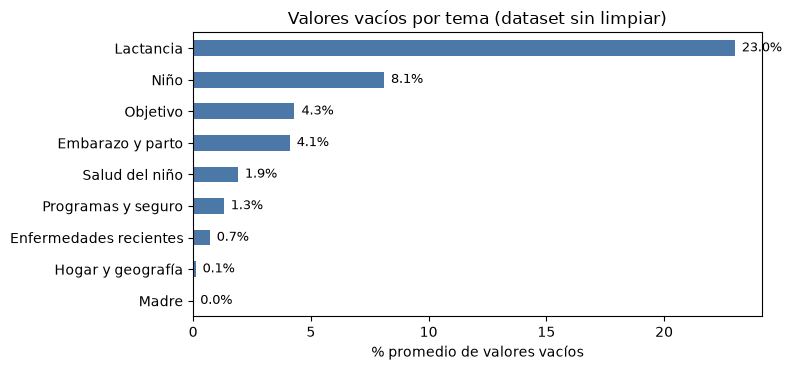

,pct_vacios
lactancia_exclusiva_6m,45.9
intervalo_nac_previo_meses,34.7


In [13]:
# % de vacíos por tema (antes de limpiar)
bloque_de = dict(zip(CAT.nombre, CAT.bloque))
vacios = df.isna().mean().mul(100).rename("pct_vacios")
por_bloque = (vacios.rename_axis("variable").reset_index()
              .assign(bloque=lambda t: t.variable.map(bloque_de).fillna("Objetivo"))
              .query("bloque != 'Llaves'")
              .groupby("bloque", sort=False).pct_vacios.mean().round(1))

fig, ax = plt.subplots(figsize=(8, 3.8))
orden = por_bloque.sort_values()
orden.plot.barh(ax=ax, color="#4C78A8")
ax.set_xlabel("% promedio de valores vacíos")
ax.set_ylabel("")
ax.set_title("Valores vacíos por tema (dataset sin limpiar)")
for i, v in enumerate(orden):
    ax.text(v + 0.3, i, f"{v:.1f}%", va="center", fontsize=9)
plt.tight_layout()
plt.show()

vacios[vacios > 15].sort_values(ascending=False).round(1).to_frame("pct_vacios")

**Lectura:** solo dos candidatas superan el 15 % de vacíos, y ambos casos son esperables: `lactancia_exclusiva_6m` (46 %, no aplica a niños menores de 6 meses) e `intervalo_nac_previo_meses` (35 %, no aplica a primogénitos ni a niños sin pareja en el puente). No son errores; se tratarán en la limpieza.

## 8. Códigos especiales y vacíos por diseño
Antes de entrenar hay que separar tres cosas que se parecen pero no son lo mismo: un **código especial** (valor numérico que significa "no sabe" o "no aplica"), un **vacío por diseño** (la pregunta no corresponde a ese niño) y un **valor real**.

In [14]:
# código -> NaN, variable por variable (se reutiliza en la limpieza del notebook 03)
NO_SABE = [8]
CODIGOS_NAN = {
    "peso_nacer_g": [9996, 9998],            # no se pesó / no sabe
    "visitas_prenatales": [98],
    "n_controles_cred": [98],
    "meses_lactancia": [98],
    "talla_madre_x10": [9999],
    "imc_madre_x100": [9998, 9999],
    "nivel_anemia_nino": [9],                # no medida
    "cloro_residual_agua": [6, 9],           # 9 = no se pudo medir; 6 = no figura en el diccionario INEI (1 178 casos)
}
for col in ["hierro_embarazo", "lactancia_exclusiva_6m", "diarrea_2sem", "tos_2sem", "hierro_jarabe_7d",
            "micronutrientes_polvo_7d", "vacuna_dpt3", "vacuna_polio3", "vacuna_sarampion",
            "hogar_juntos", "hogar_vaso_leche", "tamano_percibido_nacer"]:
    CODIGOS_NAN[col] = NO_SABE


def aplicar_codigos_especiales(datos):
    out = datos.copy()
    for col, codigos in CODIGOS_NAN.items():
        out[col] = out[col].replace(codigos, np.nan)
    out["meses_lactancia"] = out["meses_lactancia"].replace({94: 0})   # 94 = nunca amamantó -> 0 meses
    for col in ["vacuna_dpt3", "vacuna_polio3", "vacuna_sarampion"]:     # 1, 2, 3 = "sí" según la fuente -> 1
        out[col] = out[col].replace({2: 1, 3: 1})
    out["n_dormitorios"] = out["n_dormitorios"].replace(0, np.nan)
    return out


# cuántos valores afecta cada regla
afectados = {col: int(df[col].isin(cods).sum()) for col, cods in CODIGOS_NAN.items()}
afectados["meses_lactancia (94 → 0)"] = int((df["meses_lactancia"] == 94).sum())
pd.Series(afectados, name="valores convertidos").to_frame().query("`valores convertidos` > 0")

,valores convertidos
peso_nacer_g,466
visitas_prenatales,20
n_controles_cred,191
meses_lactancia,1
talla_madre_x10,352
imc_madre_x100,354
nivel_anemia_nino,1590
cloro_residual_agua,2788
hierro_embarazo,4
lactancia_exclusiva_6m,6


Tres recodificaciones que **no** son simples `NaN`:
- `meses_lactancia`: `94` (nunca amamantó) se recodifica a **0 meses** (si quedara como 94, el modelo lo leería como casi 8 años de lactancia). El código `95` ("aún amamanta") que describe el estándar DHS **no aparece** en ENDES 2025 (se verificó), así que no hace falta una variable `sigue_lactando`.
- **Vacunas:** los códigos `1`, `2` y `3` significan todos "sí" (carné con fecha, lo reporta la madre, marcada en carné); se unifican en `1` para que el modelo no los lea como niveles 0-3.
- `intervalo_nac_previo_meses`: el `999` del diccionario de RECH6 **no aparece** en este dataset; los primogénitos ya vienen vacíos (el cruce lo confirma abajo), así que `orden_nacimiento` recoge esa información sin tocar nada.

In [15]:
# Comprobación 1: ¿los vacíos del intervalo son los primogénitos?
prim = df["orden_nacimiento"] == 1
pd.DataFrame({
    "primogénitos": [prim.sum(), df.loc[prim, "intervalo_nac_previo_meses"].isna().mean().round(3)],
    "no primogénitos": [(~prim).sum(), df.loc[~prim, "intervalo_nac_previo_meses"].isna().mean().round(3)],
}, index=["niños", "proporción con intervalo vacío"])

,primogénitos,no primogénitos
niños,6027.0,12814.00
proporción con intervalo vacío,1.0,0.04


In [16]:
# Comprobación 2: vacíos por diseño según la edad del niño
grupo_edad = pd.cut(df["edad_meses"], [-1, 5, 11, 23, 59], labels=["0-5 m", "6-11 m", "12-23 m", "24-59 m"])
tmp = aplicar_codigos_especiales(df)
vac = ["nivel_anemia_nino", "hierro_jarabe_7d", "micronutrientes_polvo_7d", "lactancia_exclusiva_6m"]
print("% de vacíos (incluye los códigos especiales ya convertidos) por edad:")
tmp.groupby(grupo_edad, observed=True)[vac].apply(lambda x: x.isna().mean().mul(100)).round(1).T

% de vacíos (incluye los códigos especiales ya convertidos) por edad:


edad_meses,0-5 m,6-11 m,12-23 m,24-59 m
nivel_anemia_nino,100.0,2.2,2.5,1.7
hierro_jarabe_7d,54.0,0.1,0.1,0.1
micronutrientes_polvo_7d,54.0,0.2,0.0,0.1
lactancia_exclusiva_6m,99.3,42.0,41.8,41.2


In [17]:
# Comprobación 3: las vacunas NO quedan vacías por edad, pero el 0 no siempre significa "sin vacunar"
vacunas = ["vacuna_dpt3", "vacuna_polio3", "vacuna_sarampion"]
print("% de niños con 0 ('no recibió') por edad:")
tmp.groupby(grupo_edad, observed=True)[vacunas].apply(lambda x: (x == 0).mean().mul(100)).round(1).T

% de niños con 0 ('no recibió') por edad:


edad_meses,0-5 m,6-11 m,12-23 m,24-59 m
vacuna_dpt3,99.6,18.2,10.2,13.6
vacuna_polio3,99.8,16.8,8.6,10.9
vacuna_sarampion,99.5,98.0,13.6,6.2


**Lectura:**
- **Anemia:** no se mide en menores de 6 meses (código `9` o vacío): tras convertir el `9` a `NaN`, esa variable queda vacía en el 100 % de ese grupo y casi completa después (≈ 2 %).
- **Hierro en jarabe y micronutrientes:** solo se preguntan desde cierta edad (≈ 54 % de vacíos entre 0 y 5 meses, casi ninguno después).
- **Lactancia exclusiva:** vacía en casi todos los menores de 6 meses (aún no la completan) **y también en ≈ 40 % de los mayores**, sin que el diccionario explique el motivo; se interpretará con cuidado.
- **Vacunas:** el `0` entre 0-5 meses (DPT3) o 6-11 meses (sarampión) **no es "sin vacunar"** sino "aún no corresponde". En la limpieza conviene una variable "esquema al día para su edad" en lugar de usar el `0` tal cual.
- XGBoost maneja los `NaN`, pero los resultados (SHAP, importancia) de estas variables se leen **junto con la edad**.

**Verificado contra el diccionario oficial de INEI:** `intervalo_nac_previo_meses` es `HC63` en RECH6 (*Intervalo de los nacimientos anteriores al niño*; el nombre DHS B11 no figura en REC21) y `antiparasitario_12m` es `H43` en REC43 (*Medicamentos para parásitos intestinales en los últimos 12 meses*), de modo que la ventana de tiempo es de 12 meses.

## 9. Verificación rápida de relevancia
Prueba exprés con las 42 *features*, para confirmar que reúnen señal predictiva. Se usa un modelo de árboles potenciados sin ajustar y una división **por conglomerado**, como se hará en el modelo real. Se compara con un grupo reducido de las 11 variables más clásicas.
El modelo real (XGBoost) y la selección final por ganancia y SHAP vienen después de la limpieza.

In [18]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import roc_auc_score, average_precision_score
from sklearn.model_selection import GroupShuffleSplit

# limpieza mínima SOLO para esta prueba (la limpieza completa se hace en el notebook 03)
d = aplicar_codigos_especiales(df[df["desnutricion_cronica"].notna()])

y = d["desnutricion_cronica"].astype(int)
tr, te = next(GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=42).split(d, y, groups=d["conglomerado"]))

NUCLEO = ["edad_meses", "sexo_nino", "orden_nacimiento", "intervalo_nac_previo_meses", "nivel_anemia_nino",
          "peso_nacer_g", "talla_madre_x10", "nivel_educativo_madre", "quintil_riqueza", "area_residencia", "altitud_msnm"]


def evaluar(cols):
    mod = HistGradientBoostingClassifier(max_iter=200, learning_rate=0.05, random_state=42)
    mod.fit(d.iloc[tr][cols], y.iloc[tr])
    p = mod.predict_proba(d.iloc[te][cols])[:, 1]
    return mod, roc_auc_score(y.iloc[te], p), average_precision_score(y.iloc[te], p)


mod, auc_all, ap_all = evaluar(candidatas)
_, auc_core, ap_core = evaluar(NUCLEO)
pd.DataFrame({"AUC-ROC": [auc_all, auc_core], "AUC-PR": [ap_all, ap_core]},
             index=[f"{len(candidatas)} candidatas", f"{len(NUCLEO)} núcleo"]).round(3)

,AUC-ROC,AUC-PR
42 candidatas,0.812,0.416
11 núcleo,0.799,0.396


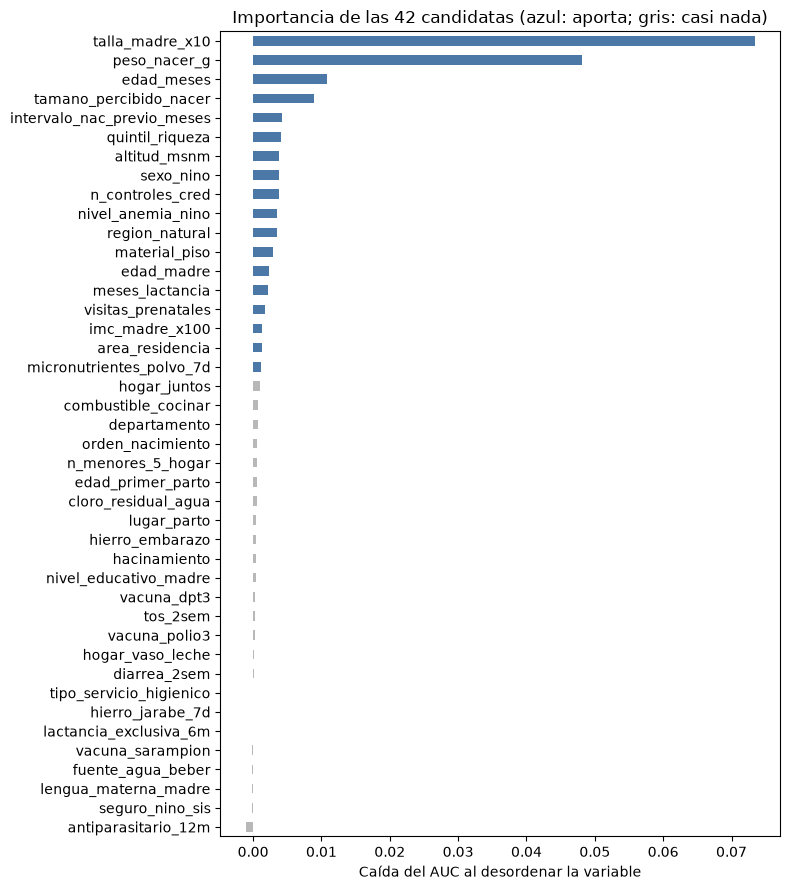

In [19]:
imp = permutation_importance(mod, d.iloc[te][candidatas], y.iloc[te], scoring="roc_auc", n_repeats=5, random_state=42)
imp = pd.Series(imp.importances_mean, index=candidatas).sort_values()

fig, ax = plt.subplots(figsize=(8, 9))
imp.plot.barh(ax=ax, color=["#4C78A8" if v > 0.001 else "#B8B8B8" for v in imp])
ax.set_xlabel("Caída del AUC al desordenar la variable")
ax.set_title("Importancia de las 42 candidatas (azul: aporta; gris: casi nada)")
plt.tight_layout()
plt.show()

**Lectura:** las 42 candidatas alcanzan AUC-ROC ≈ 0.81 y AUC-PR ≈ 0.42 (con ≈ 12 % de positivos, el azar daría 0.12), apenas por encima del núcleo de 11 variables (0.80 y 0.40). `talla_madre_x10` y `peso_nacer_g` dominan con claridad; les siguen la edad del niño, la riqueza, la región natural, el intervalo entre hijos y la altitud. Más de la mitad de las variables casi no aportan en esta prueba (vacunas, programas sociales, SIS, controles, enfermedades recientes, hacinamiento). Es una sola prueba, con los códigos especiales aún sin limpiar: sirve como pista, no como decisión. La selección final se hará con XGBoost, ganancia y SHAP.

## 10. Guardar resultados
- `dataset_integrado_crudo.csv`: una fila por niño con las 42 candidatas, **sin limpiar** los valores.
- `diccionario_variables.csv`: nombre final, **rol en el modelo**, tipo (numérica/categórica), tabla y código de origen, códigos que pasan a `NaN` y significado.

In [20]:
df.to_csv(SALIDA / "dataset_integrado_crudo.csv", index=False, encoding="utf-8")

dic = CAT[CAT.nombre.isin(df.columns)].copy()
dic = pd.concat([dic, pd.DataFrame([
    ("Objetivo", "derivada", "", "talla_edad_dest_x100", "haz", "Puntaje Z talla/edad OMS (objetivo de regresión; fuga si se usa para clasificar). Vacío si el código no es válido", "excluir", "numérica"),
    ("Objetivo", "derivada", "", "haz", "desnutricion_cronica", "1 si haz < -2, 0 en otro caso (objetivo de clasificación)", "target", "numérica"),
], columns=COLS + ["rol", "tipo"])], ignore_index=True)
dic["codigos_a_nan"] = dic["nombre"].map(lambda n: str(CODIGOS_NAN.get(n, "")).strip("[]"))
dic = dic.set_index("nombre").loc[[c for c in df.columns]].reset_index()
dic = dic[["bloque", "nombre", "rol", "tipo", "tabla", "codigo", "codigos_a_nan", "descripcion"]]
dic.to_csv(SALIDA / "diccionario_variables.csv", index=False, encoding="utf-8-sig")

print("Guardado:", "dataset_integrado_crudo.csv", "→", df.shape)
print("Guardado:", "diccionario_variables.csv", "→", dic.shape)
print()
print("Así se arman las matrices en los notebooks siguientes:")
print("  X = df[features]  con  features = dic.loc[dic.rol == 'feature', 'nombre']  ->", int((dic.rol == "feature").sum()), "variables")
print('  y = df["desnutricion_cronica"]   |   grupos = df["conglomerado"]   |   peso = df["factor_ponderacion"] / 1e6')
dic.groupby("rol").size().rename("columnas").to_frame()

Guardado: dataset_integrado_crudo.csv → (18841, 50)
Guardado: diccionario_variables.csv → (50, 8)

Así se arman las matrices en los notebooks siguientes:
  X = df[features]  con  features = dic.loc[dic.rol == 'feature', 'nombre']  -> 42 variables
  y = df["desnutricion_cronica"]   |   grupos = df["conglomerado"]   |   peso = df["factor_ponderacion"] / 1e6


,columnas
rol,
excluir,3
feature,42
grupo,1
id,2
peso,1
target,1


## 11. Resumen y siguiente paso
- **18 841 niños × 50 columnas:** 4 de apoyo (`id`, `grupo`, `peso`), 2 insumos, **42 *features*** y 2 objetivos (`haz` para regresión, `desnutricion_cronica` para clasificación, ≈ 12 % de positivos), integradas desde **15 tablas** de ENDES 2025.
- Cada columna tiene su **rol** y su **tipo** en el diccionario; los códigos especiales están documentados y convertibles con `aplicar_codigos_especiales()`.
- Las candidatas siguen la prioridad: niño, geografía, madre, embarazo, lactancia, enfermedades, salud del niño, hogar, programas.

**Cómo se decidirá la selección final:**
1. Limpiar (códigos especiales a `NaN`, duplicados, atípicos), declarar las categóricas y entrenar XGBoost con las 42 *features*, dividiendo por conglomerado y con `scale_pos_weight`.
2. Revisar la importancia por ganancia y SHAP.
3. Eliminar las que aporten casi nada y comparar el rendimiento con el modelo reducido.

**Siguiente notebook (02):** diagnóstico y EDA con los datos **sin limpiar**: estructura y tipos, estadísticos descriptivos, valores faltantes, códigos especiales, duplicados, atípicos, distribuciones y correlaciones (Semanas 03-05).